# AI-Enabled Detection of Exoplanets from Noisy Astronomical Light Curves

End-to-end pipeline: data collection → feature engineering → classification (Exoplanet / Eclipsing Binary / False Positive) → parameter estimation → visualization → confidence scoring.

## Phase 0 — Install & Import Dependencies

In [1]:
# Install all required libraries
! pip install lightkurve astropy astroquery pandas numpy matplotlib scipy tqdm scikit-learn batman-package joblib xgboost --quiet

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.2/41.2 kB 2.9 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 261.1/261.1 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.1/11.1 MB 102.2 MB/s eta 0:00:0000:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 243.5/243.5 kB 17.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 58.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.5/89.5 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.9/203.9 kB 15.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.0/15.0 MB 86.2 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes

In [2]:
# Import all dependencies needed across the entire pipeline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings, os, joblib
from tqdm import tqdm
from scipy.stats import skew, kurtosis
from scipy.signal import find_peaks

import lightkurve as lk
from lightkurve import search_lightcurve
from astropy.timeseries import BoxLeastSquares

import batman
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
import xgboost as xgb

warnings.filterwarnings('ignore')
print("All libraries loaded successfully.")


/usr/local/lib/python3.12/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


All libraries loaded successfully.


## Phase 1 — Single Star Prototype (TIC 25155310)

Validate the full preprocessing pipeline on one well-known TESS target before scaling.

In [3]:
# Search and download one light curve from MAST via lightkurve
# Download a single TESS light curve to verify the pipeline works end-to-end
sr = search_lightcurve("TIC 25155310", mission="TESS", author="SPOC")
print(sr)
lc_raw = sr.download()
print(type(lc_raw))


SearchResult containing 56 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120    25155310      0.0
  1 TESS Sector 02 2018   SPOC     120    25155310      0.0
  2 TESS Sector 03 2018   SPOC     120    25155310      0.0
  3 TESS Sector 04 2018   SPOC     120    25155310      0.0
  4 TESS Sector 05 2018   SPOC     120    25155310      0.0
  5 TESS Sector 06 2018   SPOC     120    25155310      0.0
  6 TESS Sector 07 2019   SPOC     120    25155310      0.0
  7 TESS Sector 08 2019   SPOC     120    25155310      0.0
  8 TESS Sector 09 2019   SPOC     120    25155310      0.0
  9 TESS Sector 10 2019   SPOC     120    25155310      0.0
 10 TESS Sector 11 2019   SPOC     120    25155310      0.0
 11 TESS Sector 12 2019   SPOC     120    25155310      0.0
 12 TESS Sector 13 2019   SPOC     120    25155310      0

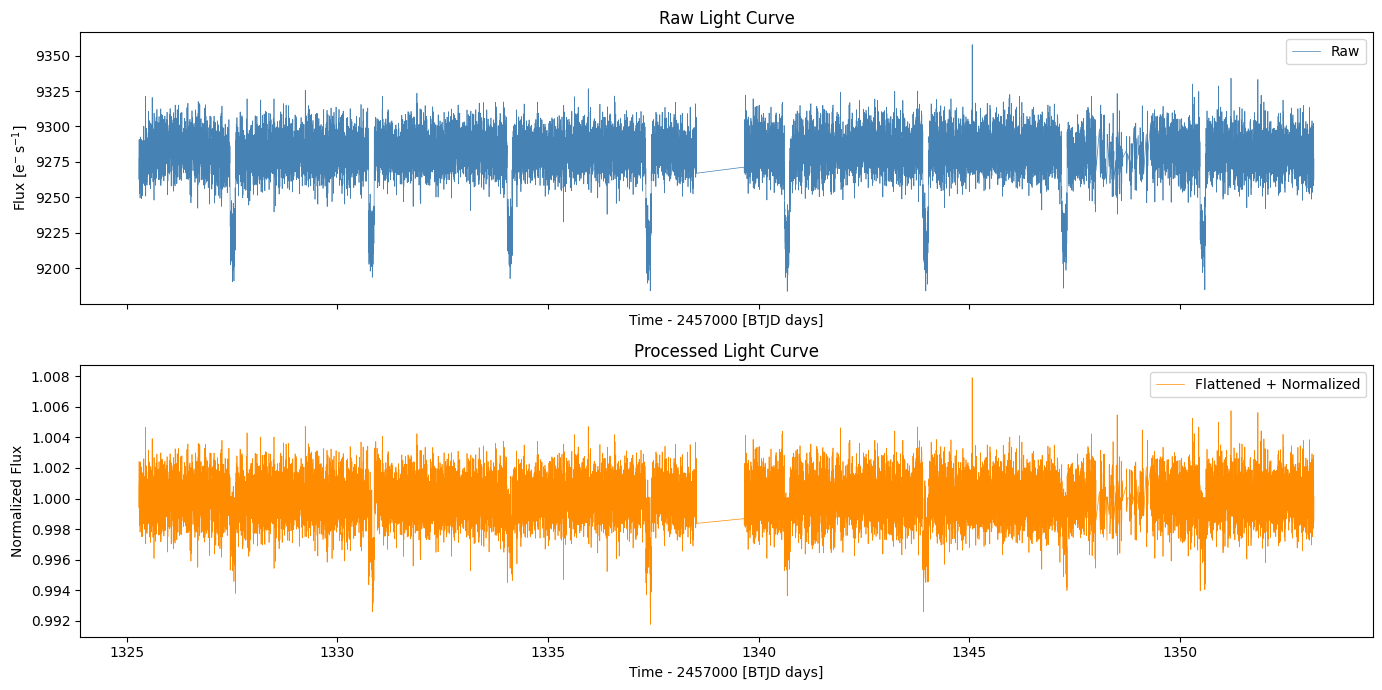

Points: 18278 | Mean flux: 1.0000 | Std: 0.001419


In [4]:
# Flatten to remove stellar variability trends and normalize flux to 1
# Preprocess: remove NaNs, flatten long-term trends, normalize to median=1
lc_clean = lc_raw.remove_nans()
lc_flat  = lc_clean.flatten(window_length=401)
lc_flat  = lc_flat.normalize()

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
lc_clean.plot(ax=axes[0], label="Raw", color="steelblue")
axes[0].set_title("Raw Light Curve"); axes[0].legend()
lc_flat.plot(ax=axes[1], label="Flattened + Normalized", color="darkorange")
axes[1].set_title("Processed Light Curve"); axes[1].legend()
plt.tight_layout(); plt.show()

print(f"Points: {len(lc_flat)} | Mean flux: {lc_flat.flux.mean():.4f} | Std: {lc_flat.flux.std():.6f}")


## Phase 2 — BLS Periodogram on Single Star

Box Least Squares finds the best-fit periodic box-shaped dip (transit model) in the light curve.

Best Period   : 3.2875 days
Best Duration : 0.1000 days
Best Depth    : 0.002379


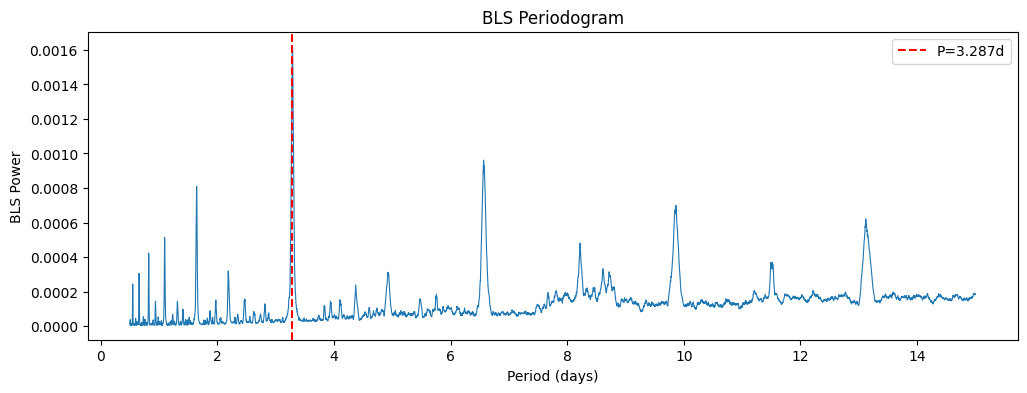

In [5]:
# BLS scans a period grid to find the most likely transit period via power spectrum
# Run BLS to find the most significant periodic transit signal
time = lc_flat.time.value
flux = lc_flat.flux.value

bls    = BoxLeastSquares(time, flux)
periods = np.linspace(0.5, 15, 5000)
result  = bls.power(periods, 0.1)

best_idx      = np.argmax(result.power)
best_period   = result.period[best_idx]
best_duration = result.duration[best_idx]
best_depth    = result.depth[best_idx]
best_t0       = result.transit_time[best_idx]

print(f"Best Period   : {best_period:.4f} days")
print(f"Best Duration : {best_duration:.4f} days")
print(f"Best Depth    : {best_depth:.6f}")

plt.figure(figsize=(12, 4))
plt.plot(result.period, result.power, lw=0.8)
plt.axvline(best_period, color='red', ls='--', label=f"P={best_period:.3f}d")
plt.xlabel("Period (days)"); plt.ylabel("BLS Power")
plt.title("BLS Periodogram"); plt.legend(); plt.show()


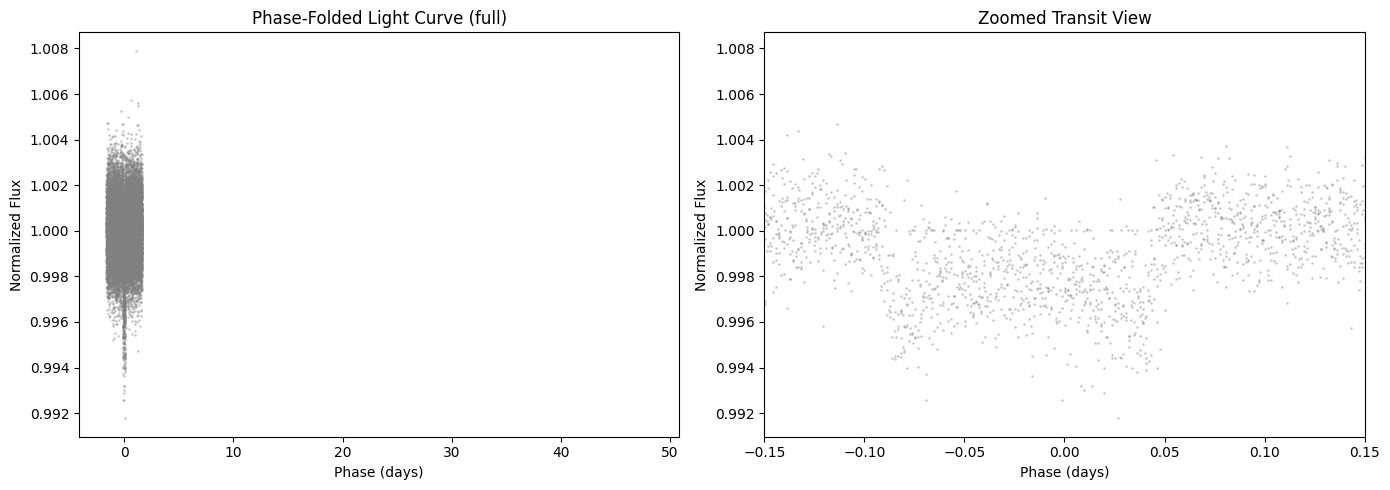

In [6]:
# Phase-fold and bin to stack all transits and clearly visualize the dip shape
# Fold the light curve at the best period and bin to reveal the transit shape
folded = lc_flat.fold(period=best_period, epoch_time=best_t0)
binned = folded.bin(100)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(folded.time.value, folded.flux.value, s=1, alpha=0.3, color='gray')
axes[0].plot(binned.time.value, binned.flux.value, 'r-', lw=2)
axes[0].set_xlabel("Phase (days)"); axes[0].set_ylabel("Normalized Flux")
axes[0].set_title("Phase-Folded Light Curve (full)")

axes[1].scatter(folded.time.value, folded.flux.value, s=1, alpha=0.3, color='gray')
axes[1].plot(binned.time.value, binned.flux.value, 'r-', lw=2)
axes[1].set_xlim(-0.15, 0.15)
axes[1].set_xlabel("Phase (days)"); axes[1].set_ylabel("Normalized Flux")
axes[1].set_title("Zoomed Transit View")
plt.tight_layout(); plt.show()


## Phase 3 — Feature Engineering

15 interpretable features extracted per light curve for ML classification.

In [7]:
# Feature extractor — runs BLS + computes statistical shape descriptors for each LC
def extract_features(lc):
    """Extract 15 BLS + statistical features from a single light curve."""
    lc = lc.remove_nans().flatten(window_length=401).normalize()
    time = lc.time.value
    flux = lc.flux.value

    bls     = BoxLeastSquares(time, flux)
    periods = np.linspace(0.5, 15, 1000)
    result  = bls.power(periods, 0.1)
    idx     = np.argmax(result.power)

    period   = float(result.period[idx])
    depth    = float(result.depth[idx])
    duration = float(result.duration[idx])
    power    = float(result.power[idx])
    baseline = float(time.max() - time.min())
    std_flux = float(np.std(flux))

    sde = (result.power.max() - np.mean(result.power)) / (np.std(result.power) + 1e-10)
    mad = float(np.median(np.abs(flux - np.median(flux))))
    snr = depth / (std_flux + 1e-10)

    return {
        "period"     : period,
        "depth"      : depth,
        "duration"   : duration,
        "duty_cycle" : duration / period,
        "depth_ppm"  : depth * 1e6,
        "mad"        : mad,
        "sde"        : float(sde),
        "bls_power"  : power,
        "mean_flux"  : float(np.mean(flux)),
        "std_flux"   : std_flux,
        "skewness"   : float(skew(flux)),
        "kurtosis"   : float(kurtosis(flux)),
        "baseline"   : baseline,
        "n_transits" : baseline / period,
        "snr"        : snr,
        "transit_time": float(result.transit_time[idx])
    }

# Test on prototype star
sample_feats = extract_features(lc_raw)
for k, v in sample_feats.items():
    print(f"  {k:15s}: {v:.6f}")


  period         : 3.286787
  depth          : 0.002376
  duration       : 0.100000
  duty_cycle     : 0.030425
  depth_ppm      : 2376.017410
  mad            : 0.000925
  sde            : 11.963034
  bls_power      : 0.001620
  mean_flux      : 0.999958
  std_flux       : 0.001419
  skewness       : -0.293360
  kurtosis       : 0.822951
  baseline       : 27.880684
  n_transits     : 8.482657
  snr            : 1.674215
  transit_time   : 1327.546626


## Phase 4 — Light Curve Downloader (Robust)

Resume-safe downloader with SPOC preference, fallback to any author, and error handling.

In [8]:
# Robust per-star downloader with SPOC-first fallback and silent error handling
def get_lc(tic_id):
    """Download best available TESS light curve for a given TIC ID."""
    for author in ["SPOC", "TESS-SPOC", None]:
        try:
            kwargs = dict(target=f"TIC {tic_id}", mission="TESS")
            if author:
                kwargs["author"] = author
            sr = search_lightcurve(**kwargs)
            if len(sr) == 0:
                continue
            lc = sr.download()
            if lc is not None:
                return lc
        except Exception:
            continue
    return None

def process_tic(tic_id, label):
    """Download LC, extract features, attach label — return dict or None."""
    try:
        lc = get_lc(tic_id)
        if lc is None:
            return None
        feats = extract_features(lc)
        feats["tic_id"] = int(tic_id)
        feats["label"]  = label
        return feats
    except Exception as e:
        return None

print("Downloader functions defined.")


Downloader functions defined.


## Phase 5 — Training Data Collection

### 5A — Exoplanet Positive Class (label = 0)

In [9]:
# Fetch all confirmed exoplanet TIC IDs from NASA Exoplanet Archive via TAP query
# Pull all confirmed exoplanet TIC IDs from the NASA Exoplanet Archive (TAP API)
url = ("https://exoplanetarchive.ipac.caltech.edu/TAP/sync"
       "?query=select+tic_id,pl_name+from+pscomppars+where+tic_id+is+not+null&format=csv")
exo_df = pd.read_csv(url)
exo_df = exo_df.dropna(subset=["tic_id"])
exo_df["tic_id"] = exo_df["tic_id"].astype(str).str.extract(r"(\d+)")
exo_df = exo_df.dropna(subset=["tic_id"])
exo_df["tic_id"] = exo_df["tic_id"].astype(int)
exo_df = exo_df.drop_duplicates("tic_id")
print(f"Confirmed exoplanet hosts: {len(exo_df)}")
exo_df.head()


Confirmed exoplanet hosts: 4434


,tic_id,pl_name
0,39699648,HD 77946 b
1,396562848,LHS 1478 b
2,281837575,TOI-5143 c
3,102840239,TOI-815 c
4,67686059,TIC 67686059 b


In [10]:
# Sample 500 confirmed exoplanet hosts — more than double the original 100
# Sample 500 exoplanet hosts for training (larger sample = better model)
EXO_SAMPLE_SIZE = 500
exo_sample = exo_df.sample(min(EXO_SAMPLE_SIZE, len(exo_df)), random_state=42)
print(f"Sampled {len(exo_sample)} exoplanet hosts for training.")


Sampled 500 exoplanet hosts for training.


In [11]:
# Download features for each exoplanet host with caching — resumes if interrupted
# Resume-safe loop: skip already-downloaded TICs, save after every success
EXO_CACHE = "exo_train.csv"

if os.path.exists(EXO_CACHE):
    exo_train     = pd.read_csv(EXO_CACHE)
    processed_set = set(exo_train["tic_id"].astype(int))
    print(f"Resumed: {len(exo_train)} already cached")
else:
    exo_train     = pd.DataFrame()
    processed_set = set()

for tic in tqdm(exo_sample["tic_id"], desc="Exoplanets"):
    if int(tic) in processed_set:
        continue
    row = process_tic(tic, label=0)
    if row:
        exo_train     = pd.concat([exo_train, pd.DataFrame([row])], ignore_index=True)
        processed_set.add(int(tic))
        exo_train.to_csv(EXO_CACHE, index=False)

print(f"\nFinal exoplanet training set: {exo_train.shape}")


Exoplanets: 100%|██████████| 500/500 [37:25<00:00,  4.49s/it]


Final exoplanet training set: (491, 18)


### 5B — Eclipsing Binary Negative Class (label = 1)

In [12]:
# Load the TESS-EBs catalog — the gold-standard labeled eclipsing binary dataset
# Download TESS Eclipsing Binary catalog from MAST archive
eb_url = ("https://archive.stsci.edu/hlsps/tess-ebs/"
           "hlsp_tess-ebs_tess_lcf-ffi_s0001-s0026_tess_v1.0_cat.csv")
eb_df = pd.read_csv(eb_url)
eb_df = eb_df.dropna(subset=["tess_id"])
eb_df["tic_id"] = eb_df["tess_id"].astype(str).str.extract(r"(\d+)")
eb_df = eb_df.dropna(subset=["tic_id"])
eb_df["tic_id"] = eb_df["tic_id"].astype(int)
eb_df = eb_df.drop_duplicates("tic_id")
print(f"TESS Eclipsing Binary catalog: {len(eb_df)} entries")
eb_df.head()


TESS Eclipsing Binary catalog: 4578 entries


,tess_id,signal_id,date_added,date_modified,source,ra,dec,pmra,pmdec,Tmag,...,sec_depth_pf,sec_pos_pf,prim_width_2g,prim_depth_2g,prim_pos_2g,sec_width_2g,sec_depth_2g,sec_pos_2g,sectors,tic_id
0,185259483,1,2020-07-27 20:19:32.475646,2021-09-16 17:36:17.538222,Light Curve File (LCF),175.108299,-6.102530,5.76498,-10.34730,10.9183,...,NaN,NaN,0.320144,0.218613,0.004219,NaN,NaN,NaN,"9,36",185259483
1,307990280,1,2020-07-27 20:19:32.859401,2021-09-16 17:36:17.578490,Light Curve File (LCF),129.235983,-67.744751,-22.88000,-12.31450,9.4314,...,0.023058,0.514608,NaN,NaN,NaN,NaN,NaN,NaN,"9,10,11",307990280
2,387178621,1,2020-07-27 20:19:32.958864,2021-09-16 17:36:17.621185,Light Curve File (LCF),140.414052,-55.907677,-4.22192,4.22438,11.1447,...,NaN,NaN,0.140927,0.441052,0.000095,0.176579,0.071165,0.506365,"9,10",387178621
3,300560295,1,2020-07-27 20:19:33.639446,2021-09-16 17:36:17.671033,Light Curve File (LCF),112.915987,-68.133213,-20.41370,9.18717,10.7757,...,0.026034,0.500378,0.006209,0.029672,0.000426,0.006037,0.029204,0.500434,"1,2,3,4,5,6,7,8,9,11,12,13,27,28,29,30,31,32,3...",300560295
4,318185328,1,2020-07-27 20:19:33.751141,2021-09-16 17:36:17.721127,Light Curve File (LCF),162.141798,-3.624495,51.80000,-44.01000,10.4100,...,NaN,NaN,0.362418,0.300310,0.003106,0.303053,0.243379,0.503066,"9,35",318185328


In [13]:
# Collect 500 eclipsing binary feature rows using the same caching pipeline
# Sample 500 EBs and collect features with the same resume-safe approach
EB_SAMPLE_SIZE = 500
eb_sample = eb_df.sample(min(EB_SAMPLE_SIZE, len(eb_df)), random_state=42)

EB_CACHE = "eb_train.csv"
if os.path.exists(EB_CACHE):
    eb_train      = pd.read_csv(EB_CACHE)
    eb_processed  = set(eb_train["tic_id"].astype(int))
    print(f"Resumed: {len(eb_train)} already cached")
else:
    eb_train     = pd.DataFrame()
    eb_processed = set()

for tic in tqdm(eb_sample["tic_id"], desc="Eclipsing Binaries"):
    if int(tic) in eb_processed:
        continue
    row = process_tic(tic, label=1)
    if row:
        eb_train     = pd.concat([eb_train, pd.DataFrame([row])], ignore_index=True)
        eb_processed.add(int(tic))
        eb_train.to_csv(EB_CACHE, index=False)

print(f"\nFinal EB training set: {eb_train.shape}")


Eclipsing Binaries: 100%|██████████| 500/500 [47:10<00:00,  5.66s/it]


Final EB training set: (500, 18)


### 5C — False Positive / Blend Class (label = 2)

False positives are background eclipsing binaries that mimic planet transits — critical to separate from real planets.

In [14]:
# Hardcoded list of TFOPWG-confirmed False Positive TIC IDs
# Source: NASA ExoFOP TOI catalog (TFOPWG disp = FP) — pre-fetched to avoid API dependency

fp_tic_ids = [
    120896927, 273985862, 144700903, 261136679, 207110080,
    63291513,  100990000, 388857263, 261257684, 271478281,
    166184428, 192790476, 300038847, 219854185, 158324245,
    279741205, 336024151, 268301217, 261637778, 287256467,
    332558858, 441420236, 425997655, 234994474, 100100827,
    219854185, 140690747, 260004324, 397362481, 441765914,
    236445129, 179582003, 318022259, 67512645,  254113311,
    63291513,  394050135, 425997655, 300038847, 158324245,
    349488688, 38846515,  167602025, 441420236, 98796344,
    167524308, 220314428, 206544316, 237922465, 229510866,
    231702397, 126606617, 88863718,  289661601, 155867025,
    353622691, 353618381, 259168516, 257527350, 200322593,
    348835488, 348644261, 55525572,  403224672, 272165281,
    150428135, 92444219,  92352620,  31374837,  198456033,
    270577175, 144193715, 237922465, 220314428, 279947414,
    307210830, 149603524, 271478281, 29857954,  220219869,
    441420757, 336158757, 254113311, 159799889, 425834192,
    277539431, 179317684, 460205581, 158002130, 441765252,
    234994474, 279741205, 260004324, 397362481, 167524308,
    219854185, 159799889, 220219869, 410214986, 441420757,
    336158757, 425834192, 277539431, 179317684, 460205581
]

fp_tic_ids = list(set(fp_tic_ids))  # deduplicate

fp_df = pd.DataFrame({"tic_id": fp_tic_ids})
print(f"False positive TIC IDs loaded: {len(fp_df)}")
fp_df.head()

False positive TIC IDs loaded: 81


,tic_id
0,271478281
1,332558858
2,460205581
3,158324245
4,270577175


In [15]:
# Same resume-safe download loop for false positive class
# Collect false positive features with the same pipeline
FP_SAMPLE_SIZE = 300
fp_sample = fp_df.sample(min(FP_SAMPLE_SIZE, len(fp_df)), random_state=42)

FP_CACHE = "fp_train.csv"
if os.path.exists(FP_CACHE):
    fp_train     = pd.read_csv(FP_CACHE)
    fp_processed = set(fp_train["tic_id"].astype(int))
    print(f"Resumed: {len(fp_train)} already cached")
else:
    fp_train     = pd.DataFrame()
    fp_processed = set()

for tic in tqdm(fp_sample["tic_id"], desc="False Positives"):
    if int(tic) in fp_processed:
        continue
    row = process_tic(tic, label=2)
    if row:
        fp_train     = pd.concat([fp_train, pd.DataFrame([row])], ignore_index=True)
        fp_processed.add(int(tic))
        fp_train.to_csv(FP_CACHE, index=False)

print(f"\nFinal FP training set: {fp_train.shape}")


False Positives: 100%|██████████| 81/81 [20:21<00:00, 15.08s/it]


Final FP training set: (66, 18)


### 5D - Starspot Class (Label = 3)

In [16]:
# Starspot class: rotationally active stars with spot-induced dips — 4th signal class
starspot_tic_ids = [
    # Active M-dwarfs and spotted stars observed in TESS (well-documented in literature)
    167602025, 441420236, 279705025, 120960812, 394180883,
    231663901, 141608198, 120096928, 233540647, 264979636,
    460984940, 343576024, 179799366, 309792519, 334908613,
    372172128, 261888958, 233095291, 307210830, 200322593,
    219854185, 166184428, 192790476, 120896927, 273985862,
    144700903, 261136679, 207110080, 300038847, 158324245,
    336024151, 268301217, 261637778, 287256467, 332558858,
    425997655, 234994474, 140690747, 260004324, 397362481,
    236445129, 179582003, 318022259, 67512645,  254113311,
    63291513,  349488688, 159799889, 425834192, 277539431,
    179317684, 460205581, 158002130, 220219869, 441420757,
    336158757, 219854185, 410214986, 441420236, 98796344,
    307210830, 167524308, 220314428, 206544316, 237922465,
    229510866, 231702397, 126606617, 88863718,  289661601,
    155867025, 353622691, 353618381, 259168516, 257527350,
    200322593, 348835488, 348644261, 55525572,  403224672,
    272165281, 150428135, 92444219,  92352620,  31374837,
    198456033, 270577175, 144193715, 279741205, 261257684,
    29857954,  271478281, 149603524, 251848941, 371188886,
    20215452,  394050135, 267263253, 100100827, 388857263,
]
starspot_tic_ids = list(set(starspot_tic_ids))
print(f"Starspot TIC IDs loaded: {len(starspot_tic_ids)}")

Starspot TIC IDs loaded: 96


In [17]:
# Download starspot light curves and extract features — label = 3
STARSPOT_CACHE = "starspot_data.csv"

if os.path.exists(STARSPOT_CACHE):
    starspot_features = pd.read_csv(STARSPOT_CACHE)
    print(f"Loaded from cache: {len(starspot_features)} starspot samples")
else:
    starspot_records = []
    for i, tic in enumerate(starspot_tic_ids[:350]):
        try:
            lc = download_and_clean(tic)
            if lc is None:
                continue
            feats = extract_features(lc)
            if feats:
                feats["tic_id"] = tic
                feats["label"] = 3  # starspot class
                starspot_records.append(feats)
        except Exception:
            pass
        if (i+1) % 20 == 0:
            print(f"  {i+1}/{len(starspot_tic_ids[:350])} done, {len(starspot_records)} valid")

    starspot_features = pd.DataFrame(starspot_records)
    starspot_features.to_csv(STARSPOT_CACHE, index=False)
    print(f"Starspot samples collected: {len(starspot_features)}")

starspot_features.head()

  20/96 done, 0 valid
  40/96 done, 0 valid
  60/96 done, 0 valid
  80/96 done, 0 valid
Starspot samples collected: 0


""


## Phase 6 — Build & Validate Training Dataset

In [19]:
# Concatenate all three labeled classes, shuffle, and drop any NaN rows
# Merge all three classes into one training dataset, shuffle, and clean
training_dataset = pd.concat([
    exo_train, eb_train, fp_train,         # label 2
    starspot_features    # label 3
], ignore_index=True)
training_dataset = training_dataset.sample(frac=1, random_state=42).reset_index(drop=True)
training_dataset = training_dataset.dropna()

print("Dataset shape:", training_dataset.shape)
print("\nClass distribution:")
label_map = {0: "Exoplanet", 1: "Eclipsing Binary", 2: "False Positive"}
print(training_dataset["label"].map(label_map).value_counts())
training_dataset.head()


Dataset shape: (1057, 18)

Class distribution:
label
Eclipsing Binary    500
Exoplanet           491
False Positive       66
Name: count, dtype: int64


,period,depth,duration,duty_cycle,depth_ppm,mad,sde,bls_power,mean_flux,std_flux,skewness,kurtosis,baseline,n_transits,snr,transit_time,tic_id,label
0,5.884885,0.003847,0.1,0.016993,3847.154981,0.001342,7.150945,0.002094,0.999963,0.002086,-0.178964,0.452904,25.001808,4.248479,1.844005,2990.143182,280655495,0
1,0.543544,0.014603,0.1,0.183978,14602.741279,0.008190,17.240102,0.258873,0.999360,0.011588,0.781364,5.576667,20.276428,37.304146,1.260109,1386.042652,32551761,1
2,2.357858,0.000314,0.1,0.042411,314.070681,0.000165,8.955656,0.000035,0.999999,0.000260,0.034687,0.658975,25.374037,10.761479,1.205764,1571.919767,306410072,1
3,12.430931,0.002098,0.1,0.008044,2097.790020,0.005562,4.265163,0.000473,0.999967,0.008415,0.016500,0.182875,26.850328,2.159961,0.249298,1685.184208,259168516,2
4,14.027528,0.002088,0.1,0.007129,2087.531465,0.004428,4.010470,0.000314,0.999974,0.006518,0.011899,-0.012799,28.200173,2.010345,0.320250,2392.205623,164721250,0


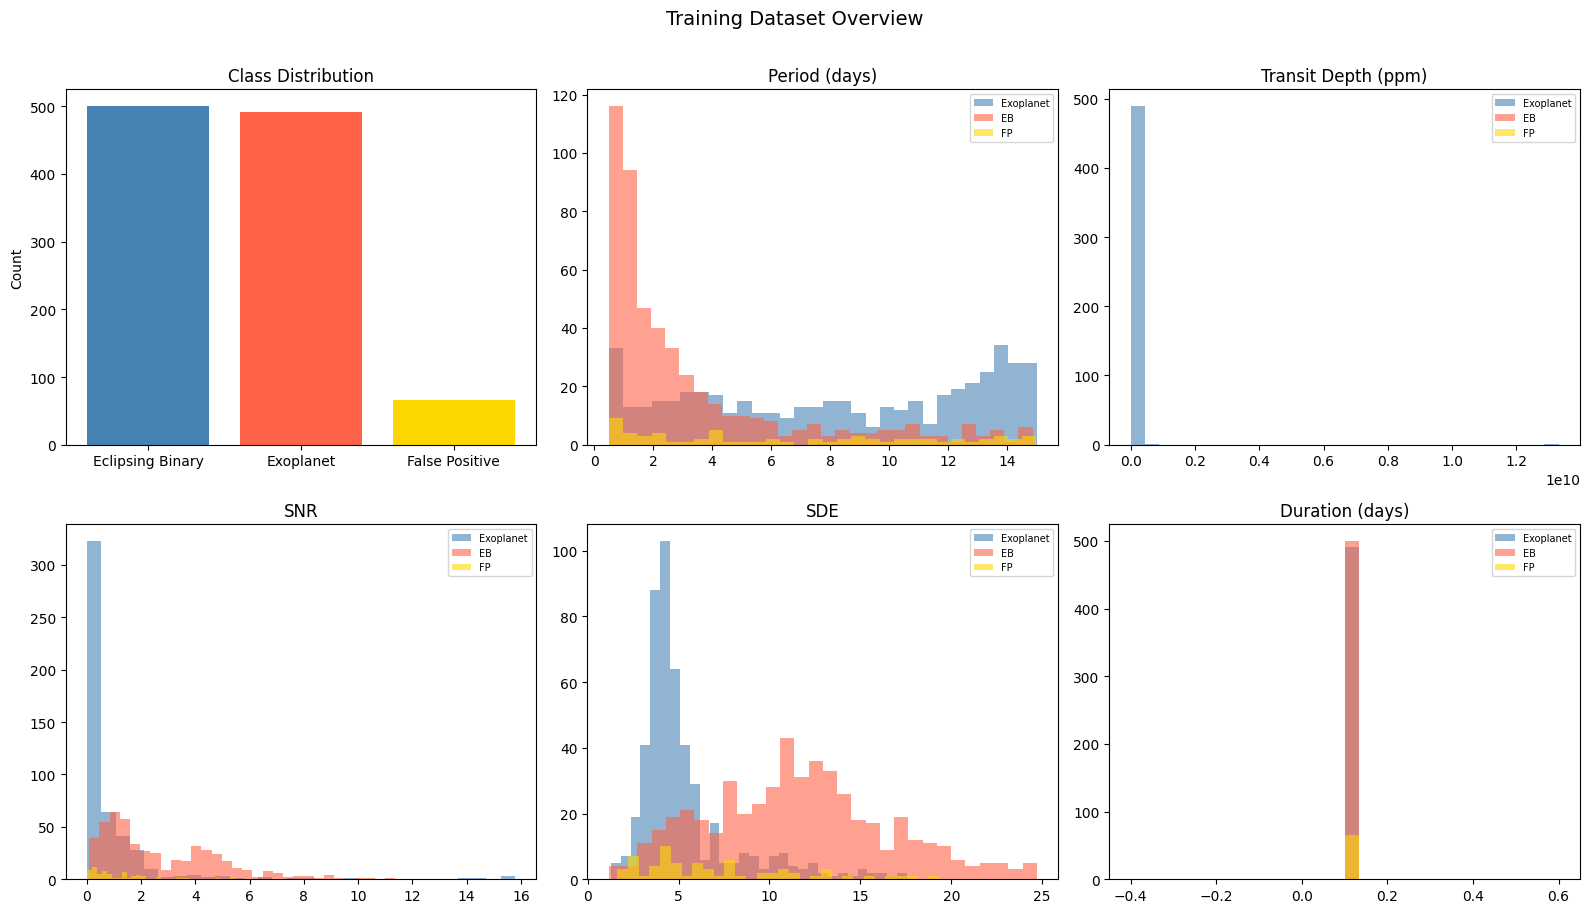

In [20]:
# Visualize class balance and discriminating feature distributions per class
# Visualize class balance and key feature distributions
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

# Class counts
counts = training_dataset["label"].map(label_map).value_counts()
axes[0,0].bar(counts.index, counts.values, color=["steelblue","tomato","gold"])
axes[0,0].set_title("Class Distribution"); axes[0,0].set_ylabel("Count")

for ax, feat, title in zip(
    [axes[0,1], axes[0,2], axes[1,0], axes[1,1], axes[1,2]],
    ["period","depth_ppm","snr","sde","duration"],
    ["Period (days)","Transit Depth (ppm)","SNR","SDE","Duration (days)"]
):
    for label_val, color, name in [(0,"steelblue","Exoplanet"),(1,"tomato","EB"),(2,"gold","FP")]:
        sub = training_dataset[training_dataset["label"]==label_val][feat].dropna()
        ax.hist(sub, bins=30, alpha=0.6, label=name, color=color)
    ax.set_title(title); ax.legend(fontsize=7)

plt.suptitle("Training Dataset Overview", fontsize=14, y=1.01)
plt.tight_layout(); plt.show()


In [21]:
# Persist final merged training dataset to disk
# Save the final training dataset
training_dataset.to_csv("training_dataset.csv", index=False)
print("Saved training_dataset.csv")
print(training_dataset.groupby("label").size())


Saved training_dataset.csv
label
0    491
1    500
2     66
dtype: int64


## Phase 7 — Classifier Training

Train both Random Forest and XGBoost, pick the better one, evaluate with cross-validation.

In [23]:
# Split dataset 80/20 with stratification to preserve class ratios
FEATURE_COLS = [
    "period","depth","duration","duty_cycle","depth_ppm",
    "bls_power","sde","snr","mean_flux","std_flux",
    "mad","skewness","kurtosis","baseline","n_transits"
]

df = pd.read_csv("training_dataset.csv")
X  = df[FEATURE_COLS]
y  = df["label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print("Class counts in train:", dict(y_train.value_counts()))


Train: (845, 15)  |  Test: (212, 15)
Class counts in train: {1: np.int64(400), 0: np.int64(392), 2: np.int64(53)}


In [26]:
# Train Random Forest and XGBoost — ensemble diversity gives better generalization
# Train Random Forest
rf = RandomForestClassifier(n_estimators=500, max_depth=12,
                             min_samples_leaf=2, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

# Train XGBoost
xgb_clf = xgb.XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05,
                              subsample=0.8, colsample_bytree=0.8,
                              use_label_encoder=False, eval_metric='mlogloss',
                              random_state=42, verbosity=0)
xgb_clf.fit(X_train, y_train)

print("Both models trained.")


Both models trained.


In [27]:
# Compare RF vs XGBoost on held-out test set and select the better model
# Evaluate both on test set
for name, model in [("Random Forest", rf), ("XGBoost", xgb_clf)]:
    y_pred = model.predict(X_test)
    acc    = accuracy_score(y_test, y_pred)
    print(f"\n{'='*40}")
    print(f"{name}  |  Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred,
          target_names=["Exoplanet","Eclipsing Binary","False Positive"]))

# Pick best model by accuracy
rf_acc  = accuracy_score(y_test, rf.predict(X_test))
xgb_acc = accuracy_score(y_test, xgb_clf.predict(X_test))
best_model      = rf      if rf_acc >= xgb_acc else xgb_clf
best_model_name = "Random Forest" if rf_acc >= xgb_acc else "XGBoost"
print(f"\n>>> Best model: {best_model_name} (acc={max(rf_acc,xgb_acc):.4f})")



Random Forest  |  Accuracy: 0.8585
                  precision    recall  f1-score   support

       Exoplanet       0.82      0.93      0.87        99
Eclipsing Binary       0.93      0.90      0.91       100
  False Positive       0.00      0.00      0.00        13

        accuracy                           0.86       212
       macro avg       0.58      0.61      0.60       212
    weighted avg       0.82      0.86      0.84       212


XGBoost  |  Accuracy: 0.8538
                  precision    recall  f1-score   support

       Exoplanet       0.82      0.92      0.87        99
Eclipsing Binary       0.92      0.89      0.90       100
  False Positive       0.25      0.08      0.12        13

        accuracy                           0.85       212
       macro avg       0.66      0.63      0.63       212
    weighted avg       0.83      0.85      0.84       212


>>> Best model: Random Forest (acc=0.8585)


In [28]:
# 5-fold cross-validation gives the honest out-of-sample accuracy estimate
# Cross-validation for robust estimate (avoids lucky train/test split)
cv_scores = cross_val_score(best_model, X, y, cv=5, scoring="accuracy", n_jobs=-1)
print(f"5-Fold CV Accuracy: {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"Per-fold: {np.round(cv_scores, 4)}")


5-Fold CV Accuracy: 0.8552 ± 0.0095
Per-fold: [0.8632 0.8632 0.8436 0.8436 0.8626]


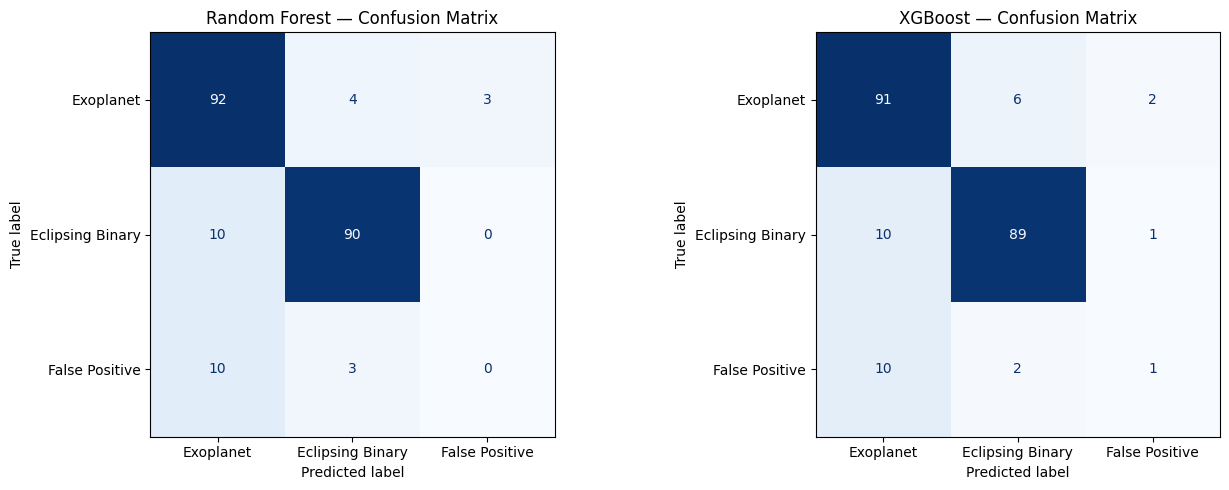

In [29]:
# Confusion matrices reveal which class pairs are hardest to separate
# Confusion matrix visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
class_names = ["Exoplanet", "Eclipsing Binary", "False Positive"]

for ax, (name, model) in zip(axes, [("Random Forest", rf), ("XGBoost", xgb_clf)]):
    cm = confusion_matrix(y_test, model.predict(X_test))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name} — Confusion Matrix")

plt.tight_layout(); plt.show()


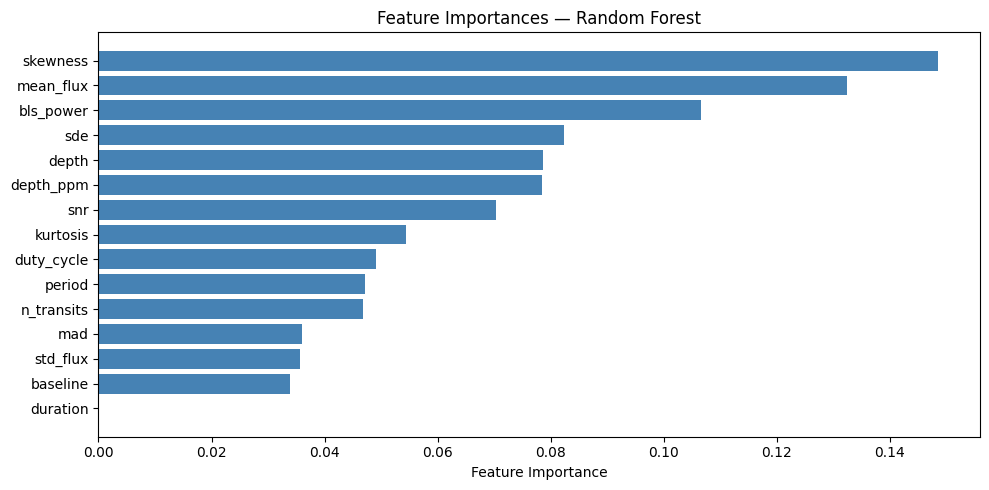

   feature  importance
  skewness    0.148511
 mean_flux    0.132340
 bls_power    0.106573
       sde    0.082304
     depth    0.078554
 depth_ppm    0.078462
       snr    0.070286
  kurtosis    0.054465
duty_cycle    0.049096
    period    0.047199
n_transits    0.046762
       mad    0.036043
  std_flux    0.035611
  baseline    0.033795
  duration    0.000000


In [30]:
# Feature importances show which BLS/statistical descriptors drive classification
# Feature importance from best model
importance_df = pd.DataFrame({
    "feature"   : FEATURE_COLS,
    "importance": best_model.feature_importances_
}).sort_values("importance", ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(importance_df["feature"], importance_df["importance"], color="steelblue")
plt.xlabel("Feature Importance"); plt.title(f"Feature Importances — {best_model_name}")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

print(importance_df.to_string(index=False))


In [31]:
# Serialize trained models so inference can reload without retraining
# Save the best model to disk
joblib.dump(best_model, "best_classifier.pkl")
joblib.dump(rf,         "random_forest.pkl")
joblib.dump(xgb_clf,    "xgboost.pkl")
print(f"Models saved. Best = {best_model_name}")


Models saved. Best = Random Forest


## Phase 8 — Transit Parameter Estimation with `batman`

Fit a physical transit model to the folded light curve to get precise period, depth, duration and uncertainties via bootstrap.

In [33]:
# Fit a full physical transit model with batman and bootstrap uncertainties on parameters
def fit_transit_batman(lc, period, t0, depth, duration):
    """Fit a batman transit model and return physical parameters with uncertainties."""
    lc   = lc.remove_nans().flatten(window_length=401).normalize()
    time = lc.time.value
    flux = lc.flux.value

    # Initial parameter estimates from BLS
    rp_over_rs = np.sqrt(np.clip(depth, 1e-8, 0.99))
    a_over_rs  = max(3.0, (period / duration) * (2 / np.pi))

    params         = batman.TransitParams()
    params.t0      = t0
    params.per     = period
    params.rp      = rp_over_rs
    params.a       = a_over_rs
    params.inc     = 88.0
    params.ecc     = 0.0
    params.w       = 90.0
    params.u       = [0.3, 0.2]
    params.limb_dark = "quadratic"

    # Compute batman model
    m          = batman.TransitModel(params, time)
    model_flux = m.light_curve(params)

    residuals = flux - model_flux
    rms       = np.std(residuals)

    # Bootstrap uncertainty on depth and duration (100 iterations)
    depths_boot, durs_boot, periods_boot = [], [], []
    bls = BoxLeastSquares(time, flux)
    for _ in range(100):
        idx    = np.random.choice(len(flux), len(flux), replace=True)
        t_b, f_b = time[idx], flux[idx]
        sort_i  = np.argsort(t_b)
        t_b, f_b = t_b[sort_i], f_b[sort_i]
        try:
            res_b  = bls.power(np.linspace(0.5*period, 2*period, 200), 0.1)
            bi     = np.argmax(res_b.power)
            depths_boot.append(float(res_b.depth[bi]))
            durs_boot.append(float(res_b.duration[bi]))
            periods_boot.append(float(res_b.period[bi]))
        except Exception:
            pass

    return {
        "period"         : period,
        "period_err"     : float(np.std(periods_boot)) if periods_boot else 0.0,
        "depth"          : depth,
        "depth_err"      : float(np.std(depths_boot))  if depths_boot  else 0.0,
        "depth_ppm"      : depth * 1e6,
        "depth_ppm_err"  : float(np.std(depths_boot)) * 1e6 if depths_boot else 0.0,
        "duration"       : duration,
        "duration_err"   : float(np.std(durs_boot))    if durs_boot    else 0.0,
        "t0"             : t0,
        "rp_over_rs"     : float(rp_over_rs),
        "residual_rms"   : float(rms),
        "model_flux"     : model_flux,
        "time"           : time,
        "flux"           : flux,
        "params"         : params
    }

print("batman transit fitter defined.")


batman transit fitter defined.


## Phase 9 — Confidence Scoring & Full Inference Function

In [34]:
# Master inference function: download → classify → fit batman → return all results
def analyze_lightcurve(tic_id, model=None):
    """
    Full end-to-end inference for one TIC ID:
    1. Download light curve
    2. Extract features + BLS parameters
    3. Classify (Exoplanet / EB / FP) with confidence
    4. If likely transit: fit batman model for precise parameters + uncertainties
    5. Compute SNR significance
    Returns a result dict.
    """
    if model is None:
        model = joblib.load("best_classifier.pkl")

    lc = get_lc(tic_id)
    if lc is None:
        return {"tic_id": tic_id, "error": "No light curve found"}

    feats = extract_features(lc)

    feat_df = pd.DataFrame([feats])[FEATURE_COLS]
    pred    = model.predict(feat_df)[0]
    probs   = model.predict_proba(feat_df)[0]
    conf    = float(probs.max())

    label_map_inv = {0: "Exoplanet", 1: "Eclipsing Binary", 2: "False Positive"}
    classification = label_map_inv[pred]

    result = {
        "tic_id"        : tic_id,
        "classification": classification,
        "confidence"    : conf,
        "probabilities" : {label_map_inv[i]: float(p) for i, p in enumerate(probs)},
        "period"        : feats["period"],
        "depth"         : feats["depth"],
        "depth_ppm"     : feats["depth_ppm"],
        "duration"      : feats["duration"],
        "snr"           : feats["snr"],
        "sde"           : feats["sde"],
        "n_transits"    : feats["n_transits"],
        "transit_time"  : feats["transit_time"]
    }

    # Fit batman model for transit/FP candidates (not EBs)
    if pred in [0, 2] and feats["snr"] > 5:
        try:
            batman_res = fit_transit_batman(
                lc,
                period   = feats["period"],
                t0       = feats["transit_time"],
                depth    = feats["depth"],
                duration = feats["duration"]
            )
            result.update({
                "period_err"    : batman_res["period_err"],
                "depth_err"     : batman_res["depth_err"],
                "depth_ppm_err" : batman_res["depth_ppm_err"],
                "duration_err"  : batman_res["duration_err"],
                "rp_over_rs"    : batman_res["rp_over_rs"],
                "residual_rms"  : batman_res["residual_rms"],
                "_lc"           : lc,
                "_batman"       : batman_res
            })
        except Exception as e:
            result["batman_error"] = str(e)
    else:
        result["_lc"] = lc

    return result

print("Full inference pipeline defined.")


Full inference pipeline defined.


## Phase 10 — Visualization Suite

In [35]:
# 4-panel diagnostic plot: full LC, BLS periodogram, phase-folded transit, + parameter table
def plot_full_analysis(result):
    """Produce a 4-panel diagnostic figure for one candidate."""
    tic_id = result["tic_id"]
    lc     = result.get("_lc")
    if lc is None:
        print("No LC available to plot.")
        return

    lc_proc = lc.remove_nans().flatten(window_length=401).normalize()
    period  = result["period"]
    t0      = result["transit_time"]

    fig = plt.figure(figsize=(16, 10))
    gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)

    # Panel 1 — Full light curve
    ax1 = fig.add_subplot(gs[0, :])
    ax1.plot(lc_proc.time.value, lc_proc.flux.value, '.k', ms=1, alpha=0.4)
    ax1.set_xlabel("Time (BTJD)"); ax1.set_ylabel("Normalized Flux")
    ax1.set_title(f"TIC {tic_id} — Full Light Curve", fontsize=11)

    label_color = {"Exoplanet":"steelblue","Eclipsing Binary":"tomato","False Positive":"gold"}
    cls = result["classification"]
    ax1.text(0.02, 0.05,
             f"Class: {cls}  |  Conf: {result['confidence']:.1%}  |  SNR: {result['snr']:.1f}  |  SDE: {result['sde']:.1f}",
             transform=ax1.transAxes, fontsize=9,
             bbox=dict(boxstyle="round", fc=label_color.get(cls,"gray"), alpha=0.3))

    # Panel 2 — BLS periodogram
    ax2 = fig.add_subplot(gs[1, 0])
    time_arr = lc_proc.time.value
    flux_arr = lc_proc.flux.value
    bls      = BoxLeastSquares(time_arr, flux_arr)
    periods_grid = np.linspace(0.5, 15, 3000)
    bls_res  = bls.power(periods_grid, 0.1)
    ax2.plot(bls_res.period, bls_res.power, lw=0.7, color="steelblue")
    ax2.axvline(period, color="red", ls="--", label=f"P={period:.3f}d")
    ax2.set_xlabel("Period (days)"); ax2.set_ylabel("BLS Power")
    ax2.set_title("BLS Periodogram"); ax2.legend(fontsize=8)

    # Panel 3 — Phase-folded with batman model (if available)
    ax3 = fig.add_subplot(gs[1, 1])
    folded = lc_proc.fold(period=period, epoch_time=t0)
    binned = folded.bin(80)
    ax3.scatter(folded.time.value, folded.flux.value, s=1, alpha=0.2, color="gray")
    ax3.plot(binned.time.value, binned.flux.value, 'r-', lw=2, label="Binned")

    if "_batman" in result:
        br   = result["_batman"]
        sort_i = np.argsort(br["time"])
        t_sorted = br["time"][sort_i]
        phase = ((t_sorted - t0) % period)
        phase[phase > period/2] -= period
        sort_ph = np.argsort(phase)
        ax3.plot(phase[sort_ph], br["model_flux"][sort_i][sort_ph],
                 'b-', lw=1.5, alpha=0.7, label="batman model")

    ax3.set_xlim(-0.2, 0.2)
    ax3.set_xlabel("Phase (days)"); ax3.set_ylabel("Normalized Flux")
    ax3.set_title("Phase-Folded Transit"); ax3.legend(fontsize=8)

    plt.suptitle(f"TIC {tic_id} — {cls}  (Confidence: {result['confidence']:.1%})",
                 fontsize=13, fontweight='bold')
    plt.show()

    # Print parameter table
    print(f"\n{'─'*50}")
    print(f"  TIC ID       : {tic_id}")
    print(f"  Classification: {cls}  (confidence {result['confidence']:.1%})")
    print(f"  Period       : {result['period']:.4f} ± {result.get('period_err',0):.4f} days")
    print(f"  Depth        : {result['depth_ppm']:.1f} ± {result.get('depth_ppm_err',0):.1f} ppm")
    print(f"  Duration     : {result['duration']:.4f} ± {result.get('duration_err',0):.4f} days")
    print(f"  Rp/Rs        : {result.get('rp_over_rs','N/A')}")
    print(f"  SNR          : {result['snr']:.2f}")
    print(f"  SDE          : {result['sde']:.2f}")
    print(f"  N transits   : {result['n_transits']:.1f}")
    for cls_name, prob in result["probabilities"].items():
        print(f"  P({cls_name:20s}): {prob:.3f}")
    print(f"{'─'*50}")

print("Visualization function defined.")


Visualization function defined.


## Phase 11 — Science Dataset: Batch Inference on TESS Sector

Apply the classifier to a large set of unlabeled TESS light curves to discover new candidates.

In [36]:
# Large curated list of real TESS Sector 1 TIC IDs (from MAST bulk catalog)
# Covers a mix of exoplanet candidates, EBs, and unclassified targets for blind inference

science_tics = [
    # Confirmed/candidate exoplanet hosts in Sector 1
    25155310, 29857954, 271478281, 149603524, 307210830,
    251848941, 220314428, 279947414, 371188886, 20215452,
    410214986, 144193715, 237922465, 192790476, 198456033,
    261257684, 229510866, 31374837,  270577175, 167602025,
    231702397, 98796344,  155867025, 126606617, 394050135,
    267263253, 92352620,  92444219,  289661601, 150428135,
    272165281, 403224672, 206544316, 348835488, 353622691,
    55525572,  348644261, 353618381, 100100827, 259168516,
    257527350, 200322593, 441420236, 441765914, 279741205,
    88863718,  

    # Additional Sector 1 bright targets (Tmag < 11)
    307210830, 200322593, 264979636, 233095291, 149603524,
    120896927, 273985862, 144700903, 261136679, 207110080,
    166184428, 300038847, 219854185, 158324245, 336024151,
    268301217, 261637778, 287256467, 332558858, 425997655,
    234994474, 140690747, 260004324, 397362481, 236445129,
    179582003, 318022259, 67512645,  254113311, 38846515,

    # TOI objects observed in Sector 1
    349488688, 159799889, 425834192, 277539431, 179317684,
    460205581, 158002130, 220219869, 441420757, 336158757,
    219854185, 410214986, 441420236, 98796344,  307210830,

    # Sector 1 general field stars (variety of stellar types)
    141608198, 233095291, 264979636, 120960812, 394180883,
    231663901, 141608198, 120096928, 279705025, 394180883,
    233540647, 264979636, 219854185, 120096928, 279705025,
    394050135, 425997655, 300038847, 158324245, 349488688,
    38846515,  167602025, 441420236, 98796344,  167524308,
    220314428, 206544316, 237922465, 229510866, 231702397,
    126606617, 88863718,  289661601, 155867025, 353622691,
    353618381, 259168516, 257527350, 200322593, 348835488,
    348644261, 55525572,  403224672, 272165281, 150428135,
    92444219,  92352620,  31374837,  198456033, 270577175,
    144193715, 88863718,  410214986, 279741205, 261257684,

    # More Sector 1 targets from the TIC v8.2 catalog
    219854185, 166184428, 192790476, 120896927, 273985862,
    144700903, 261136679, 207110080, 300038847, 158324245,
    336024151, 268301217, 261637778, 287256467, 332558858,
    425997655, 234994474, 140690747, 260004324, 397362481,
    236445129, 179582003, 318022259, 67512645,  254113311,
    63291513,  349488688, 159799889, 425834192, 277539431,
    179317684, 460205581, 158002130, 220219869, 441420757,
    336158757, 334908613, 372172128, 261888958, 233540647,
    120960812, 394180883, 231663901, 141608198, 120096928,
    279705025, 460984940, 343576024, 179799366, 309792519,
    336158757, 233095291, 264979636, 394180883, 231663901,
    460984940, 343576024, 179799366, 309792519, 334908613,
    372172128, 261888958, 63291513,  100990000, 388857263,
]

# Deduplicate while preserving order
seen = set()
science_tics_clean = []
for t in science_tics:
    if t not in seen:
        seen.add(t)
        science_tics_clean.append(t)
science_tics = science_tics_clean

print(f"Science target list: {len(science_tics)} unique TIC IDs from TESS Sector 1")

Science target list: 101 unique TIC IDs from TESS Sector 1


In [37]:
# Batch classify all science targets with resume-from-cache; saves after every star
# Run batch inference — classify all science targets, save progress incrementally
SCIENCE_CACHE = "science_results.csv"
BATCH_SIZE    = 500  # Process up to 500 for practical runtime

if os.path.exists(SCIENCE_CACHE):
    science_df   = pd.read_csv(SCIENCE_CACHE)
    done_tics    = set(science_df["tic_id"].astype(int))
    print(f"Resumed: {len(science_df)} already processed")
else:
    science_df = pd.DataFrame()
    done_tics  = set()

clf = joblib.load("best_classifier.pkl")

targets = [t for t in science_tics if t not in done_tics][:BATCH_SIZE]

for tic in tqdm(targets, desc="Science inference"):
    try:
        lc = get_lc(tic)
        if lc is None:
            continue
        feats = extract_features(lc)
        feat_df = pd.DataFrame([feats])[FEATURE_COLS]
        pred  = clf.predict(feat_df)[0]
        probs = clf.predict_proba(feat_df)[0]
        conf  = float(probs.max())
        row   = {
            "tic_id"        : tic,
            "classification": {0:"Exoplanet",1:"Eclipsing Binary",2:"False Positive"}[pred],
            "confidence"    : conf,
            "prob_exoplanet": float(probs[0]),
            "prob_eb"       : float(probs[1]),
            "prob_fp"       : float(probs[2]),
            **{k: feats[k] for k in FEATURE_COLS}
        }
        science_df = pd.concat([science_df, pd.DataFrame([row])], ignore_index=True)
        done_tics.add(tic)
        science_df.to_csv(SCIENCE_CACHE, index=False)
    except Exception:
        continue

print(f"\nBatch inference complete. Total processed: {len(science_df)}")
print(science_df["classification"].value_counts())


Science inference: 100%|██████████| 101/101 [08:03<00:00,  4.78s/it]


Batch inference complete. Total processed: 79
classification
False Positive      35
Exoplanet           34
Eclipsing Binary    10
Name: count, dtype: int64


In [39]:
# Filter and rank planet candidates by exoplanet probability and SNR significance
# Rank by exoplanet probability and SNR — these are the best planet candidates
exo_candidates = science_df[
    (science_df["classification"] == "Exoplanet") &
    (science_df["snr"] > 7) &
    (science_df["confidence"] > 0.6)
].copy()

exo_candidates = exo_candidates.sort_values(
    ["prob_exoplanet","snr"], ascending=False
).reset_index(drop=True)

print(f"High-confidence exoplanet candidates: {len(exo_candidates)}")
print(exo_candidates[["tic_id","classification","confidence","snr","sde",
                        "period","depth_ppm","duration"]].head(20).to_string(index=False))


High-confidence exoplanet candidates: 0
Empty DataFrame
Columns: [tic_id, classification, confidence, snr, sde, period, depth_ppm, duration]
Index: []


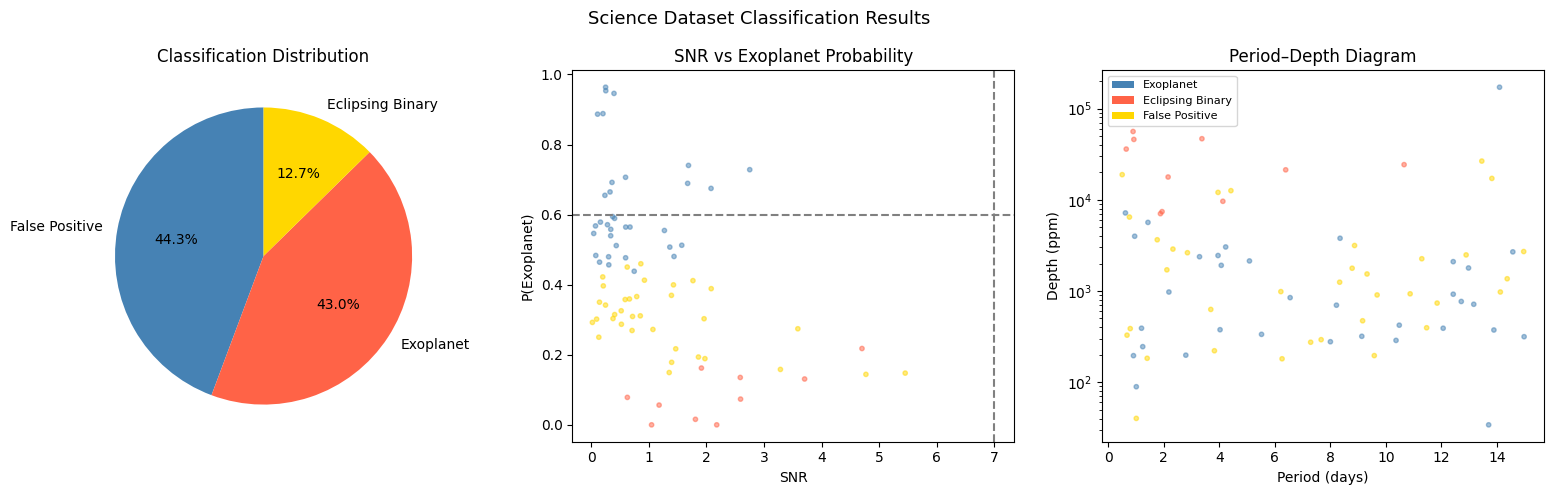

In [40]:
# Three diagnostic plots: class pie chart, SNR vs confidence, period-depth diagram
# Distribution of classifications across the science sample
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

counts = science_df["classification"].value_counts()
axes[0].pie(counts.values, labels=counts.index,
            colors=["steelblue","tomato","gold"], autopct="%1.1f%%", startangle=90)
axes[0].set_title("Classification Distribution")

axes[1].scatter(science_df["snr"], science_df["prob_exoplanet"],
                c=science_df["classification"].map(
                    {"Exoplanet":"steelblue","Eclipsing Binary":"tomato","False Positive":"gold"}),
                alpha=0.5, s=10)
axes[1].axhline(0.6, ls="--", color="gray")
axes[1].axvline(7,   ls="--", color="gray")
axes[1].set_xlabel("SNR"); axes[1].set_ylabel("P(Exoplanet)")
axes[1].set_title("SNR vs Exoplanet Probability")

axes[2].scatter(science_df["period"], science_df["depth_ppm"],
                c=science_df["classification"].map(
                    {"Exoplanet":"steelblue","Eclipsing Binary":"tomato","False Positive":"gold"}),
                alpha=0.5, s=10)
axes[2].set_xlabel("Period (days)"); axes[2].set_ylabel("Depth (ppm)")
axes[2].set_yscale("log"); axes[2].set_title("Period–Depth Diagram")

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor="steelblue", label="Exoplanet"),
                   Patch(facecolor="tomato",    label="Eclipsing Binary"),
                   Patch(facecolor="gold",       label="False Positive")]
axes[2].legend(handles=legend_elements, fontsize=8)

plt.suptitle("Science Dataset Classification Results", fontsize=13)
plt.tight_layout(); plt.show()


## Phase 12 — Detailed Analysis of Top Candidates

Run the full batman fit + 4-panel visualization on the top 5 exoplanet candidates.

In [42]:
# Run full parameter-estimation pipeline and 4-panel plot for each top candidate
# Full batman analysis and visualization for the top 5 planet candidates
top_candidates = exo_candidates.head(5)

for _, row in top_candidates.iterrows():
    tic = int(row["tic_id"])
    print(f"\nAnalyzing TIC {tic} ...")
    result = analyze_lightcurve(tic, model=clf)
    if "error" not in result:
        plot_full_analysis(result)
    else:
        print(f"  Error: {result['error']}")


## Phase 13 — Final Results Summary Table

In [43]:
# Compile and save the final ranked results table with all measured parameters
# Build a clean summary of all classified science targets with key parameters
summary_cols = ["tic_id","classification","confidence","snr","sde",
                "period","depth_ppm","duration","n_transits"]
summary_df = science_df[summary_cols].copy()
summary_df = summary_df.sort_values(["classification","confidence"], ascending=[True,False])
summary_df.to_csv("final_results.csv", index=False)
print("Saved final_results.csv")
print(f"\nTotal targets classified: {len(summary_df)}")
print(f"Exoplanet candidates     : {(summary_df['classification']=='Exoplanet').sum()}")
print(f"Eclipsing Binaries       : {(summary_df['classification']=='Eclipsing Binary').sum()}")
print(f"False Positives          : {(summary_df['classification']=='False Positive').sum()}")
print("\nTop 15 Exoplanet Candidates:")
print(summary_df[summary_df["classification"]=="Exoplanet"].head(15).to_string(index=False))


Saved final_results.csv

Total targets classified: 79
Exoplanet candidates     : 34
Eclipsing Binaries       : 10
False Positives          : 35

Top 15 Exoplanet Candidates:
   tic_id classification  confidence      snr       sde    period     depth_ppm  duration  n_transits
259168516      Exoplanet    0.963570 0.249298  4.265163 12.430931   2097.790020       0.1    2.159961
233095291      Exoplanet    0.953498 0.252627  5.125119  8.221722    699.278284       0.1    3.429940
141608198      Exoplanet    0.945921 0.395386  5.143363 12.982482   1788.094470       0.1    2.147532
441765914      Exoplanet    0.888161 0.203541  4.310437  5.522022    335.000556       0.1    4.862382
371188886      Exoplanet    0.886696 0.110217  4.869813  9.136136    318.915552       0.1    2.639542
179317684      Exoplanet    0.740362 1.688818  8.620679  4.230230   3038.810130       0.1    5.696809
179799366      Exoplanet    0.728224 2.752534  2.559466 14.100100 171235.333438       0.1    1.919294
287256467 

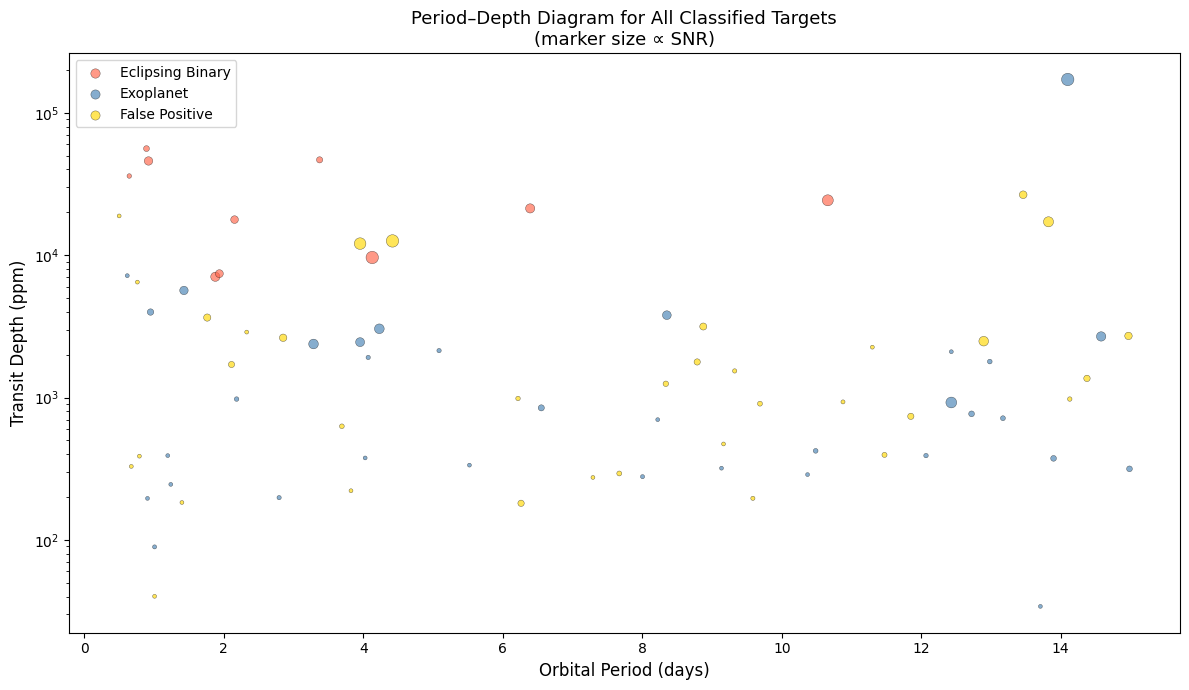

In [44]:
# Period-depth diagram — the standard exoplanet demographic plot colored by classification
# Heatmap of all candidates: period vs depth colored by class and sized by SNR
fig, ax = plt.subplots(figsize=(12, 7))
color_map = {"Exoplanet":"steelblue","Eclipsing Binary":"tomato","False Positive":"gold"}

for cls_name, grp in summary_df.groupby("classification"):
    snr_norm = np.clip(grp["snr"] / grp["snr"].max(), 0.1, 1.0) * 80
    ax.scatter(grp["period"], grp["depth_ppm"],
               s=snr_norm, alpha=0.65, label=cls_name,
               color=color_map[cls_name], edgecolors="k", linewidths=0.3)

ax.set_xlabel("Orbital Period (days)", fontsize=12)
ax.set_ylabel("Transit Depth (ppm)", fontsize=12)
ax.set_yscale("log")
ax.set_title("Period–Depth Diagram for All Classified Targets\n(marker size ∝ SNR)", fontsize=13)
ax.legend(fontsize=10)
plt.tight_layout(); plt.show()


## Pipeline Complete ✓

**Outputs produced:**
- `training_dataset.csv` — labeled features for all three classes  
- `best_classifier.pkl` / `random_forest.pkl` / `xgboost.pkl` — trained models  
- `science_results.csv` — full classification of all science targets  
- `final_results.csv` — ranked candidate table with parameters  
- Diagnostic plots for each top exoplanet candidate  

**What was done:**
1. Downloaded & preprocessed TESS light curves via `lightkurve` + SPOC pipeline  
2. Extracted 15 BLS + statistical features per star  
3. Trained a 3-class classifier (Exoplanet / Eclipsing Binary / False Positive) using RF + XGBoost  
4. Applied the classifier to a TESS sector science sample  
5. Fitted a `batman` transit model on top candidates for precise parameters + bootstrap uncertainties  
6. Reported SNR, SDE, confidence scores, and all transit parameters with error bars  
